# Preserving memory with a fixed-width operator

The fixed-width rule stops before the first weight smaller than a chosen cutoff and uses the same retained weights at every valid time:

$$
m_{\tau}(d)=\min\{m\geq1:|\omega_m|<\tau\},\qquad
\widetilde X_t^{(d,\tau)}=\sum_{k=0}^{m_{\tau}(d)-1}\omega_kX_{t-k}.
$$

Here, $d$ is the difference order; $\tau>0$ is the absolute-weight cutoff; $m_{\tau}(d)$ is the first excluded lag. $\omega_k$ is the lag-$k$ weight; $X_{t-k}$ is the level $k$ steps before $t$; $\widetilde X_t^{(d,\tau)}$ is the transformed value.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
from scipy.signal import fftconvolve
from statsmodels.tsa.stattools import adfuller

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.data.differentiation import adaptive_fractional_difference, calculate_weights_ffd, calculate_weights_std, fractional_difference_fixed, fractional_difference_fixed_single, fractional_difference_std

FIGURES = ROOT / "outputs" / "figures" / "08_fractional_differentiation"
TABLES = ROOT / "outputs" / "tables" / "08_fractional_differentiation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def natural_weights(degree, size):
    values = [1.0]
    for k in range(1, size):
        values.append(-values[-1] * (degree - k + 1) / k)
    return np.asarray(values, dtype=float)

def adf_record(values):
    result = adfuller(np.asarray(values, dtype=float), maxlag=1, regression="c", autolag=None)
    return {"ADF statistic": float(result[0]), "p-value": float(result[1]), "Used lag": int(result[2]), "Observations in test": int(result[3]), "Five percent critical value": float(result[4]["5%"]) }

raw = raw.sort_values("time").dropna(subset=["time", "close"]).drop_duplicates("time").reset_index(drop=True)
minute_close = pd.Series(raw["close"].to_numpy(dtype=float), index=pd.DatetimeIndex(raw["time"]), name="One-minute close")
close = minute_close.resample("15min").last().dropna().rename("Fifteen-minute close")
log_price = np.log(close).rename("Log price")
log_frame = log_price.rename("close").to_frame()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Constant Windows

In [2]:
width_rows = []
for threshold in [1e-2, 1e-3, 1e-4]:
    for degree in [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
        weights = calculate_weights_ffd(degree, threshold).flatten()[::-1]
        next_lag = len(weights)
        next_weight = -weights[-1] * (degree - next_lag + 1) / next_lag
        width_rows.append({"Cutoff": threshold, "Order": degree, "Retained weights": len(weights), "Warm-up records": len(weights) - 1, "Smallest retained absolute weight": np.min(np.abs(weights)), "First excluded absolute weight": abs(next_weight), "Retained signed sum": weights.sum()})
window_width_summary = pd.DataFrame(width_rows)
transform_rows = []
fixed_outputs = {}
for degree in [0.0, 0.1, 0.2, 0.5, 1.0]:
    transformed = fractional_difference_fixed(log_frame, degree, threshold=1e-3).dropna()["close"]
    fixed_outputs[degree] = transformed
    record = adf_record(transformed)
    transform_rows.append({"Order": degree, "Retained weights": len(calculate_weights_ffd(degree, 1e-3)), "Usable observations": len(transformed), "Mean": transformed.mean(), "Standard deviation": transformed.std(ddof=1), "Correlation with log price": np.corrcoef(log_price.loc[transformed.index], transformed)[0, 1], "ADF p-value": record["p-value"]})
fixed_transform_summary = pd.DataFrame(transform_rows)
degree = 0.4
expanding = fractional_difference_std(log_frame, degree, threshold=0.01).dropna()["close"]
fixed = fractional_difference_fixed(log_frame, degree, threshold=1e-3).dropna()["close"]
comparison_rows = []
for name, values in [("Expanding window", expanding), ("Fixed width", fixed)]:
    elapsed_days = (values.index - values.index[0]).total_seconds() / 86400
    slope = np.polyfit(elapsed_days, values.to_numpy(), 1)[0]
    comparison_rows.append({"Method": name, "Usable observations": len(values), "First usable time": str(values.index[0]), "Mean": values.mean(), "Standard deviation": values.std(ddof=1), "Linear slope per day": slope, "Correlation with log price": np.corrcoef(log_price.loc[values.index], values)[0, 1]})
expanding_fixed_summary = pd.DataFrame(comparison_rows)
save_table(window_width_summary, "window_width_summary", "Fixed-width lengths under three absolute-weight cutoffs.", "tab:chapter7-window-width", fit=True)
save_table(fixed_transform_summary, "fixed_transform_summary", "Public-data fixed-width results at a cutoff of 0.001.", "tab:chapter7-fixed-transform", fit=True)
save_table(expanding_fixed_summary, "expanding_fixed_summary", "Expanding-window and fixed-width results for order 0.4.", "tab:chapter7-expanding-fixed", fit=True)
display(window_width_summary)
display(fixed_transform_summary.round(8))
display(expanding_fixed_summary.round(8))

,Cutoff,Order,Retained weights,Warm-up records,Smallest retained absolute weight,First excluded absolute weight,Retained signed sum
0,0.0100,0.1,8,7,0.011094,0.009568,0.765465
1,0.0100,0.2,11,10,0.010973,0.009776,0.537678
2,0.0100,0.4,11,10,0.011006,0.009606,0.264154
3,0.0100,0.6,9,8,0.010340,0.008502,0.127531
4,0.0100,0.8,6,5,0.011264,0.007885,0.059136
5,0.0100,1,2,1,1,0,0
6,0.0010,0.1,62,61,0.001018,0.001000,0.619898
7,0.0010,0.2,73,72,0.001016,0.000999,0.364765
8,0.0010,0.4,55,54,0.001014,0.000988,0.135871
9,0.0010,0.6,34,33,0.001021,0.000973,0.055121


,Order,Retained weights,Usable observations,Mean,Standard deviation,Correlation with log price,ADF p-value
0,0,1,2976,10.445796,0.084958,1,4.883794e-02
1,0.1,62,2915,6.477617,0.052402,0.994719,1.565530e-03
2,0.2,73,2904,3.812005,0.032571,0.966637,3.000000e-07
3,0.5,44,2933,0.896488,0.011711,0.691952,0
4,1,2,2975,0.000047,0.007798,0.038133,0


,Method,Usable observations,First usable time,Mean,Standard deviation,Linear slope per day,Correlation with log price
0,Expanding window,768,2021-01-24 00:00:00,0.300575,0.014431,-0.003566,0.302770
1,Fixed width,2922,2021-01-01 13:30:00,1.419891,0.015289,-0.000331,0.816566


## Truncation Error

If the omitted past levels are bounded, the error from cutting the weight tail is no larger than their bound times the omitted absolute weight:

$$
\left|\sum_{k=m}^{\infty}\omega_kX_{t-k}\right|
\leq M_t\sum_{k=m}^{\infty}|\omega_k|,qquad
M_t=\sup_{k\geq m}|X_{t-k}|.
$$

Here, $m$ is the first omitted lag; $\omega_k$ is the weight at lag $k$; $X_{t-k}$ is the omitted past level. $M_t$ is the largest absolute omitted level at time $t$; $\sup$ denotes the least upper bound; $|\cdot|$ is absolute value.

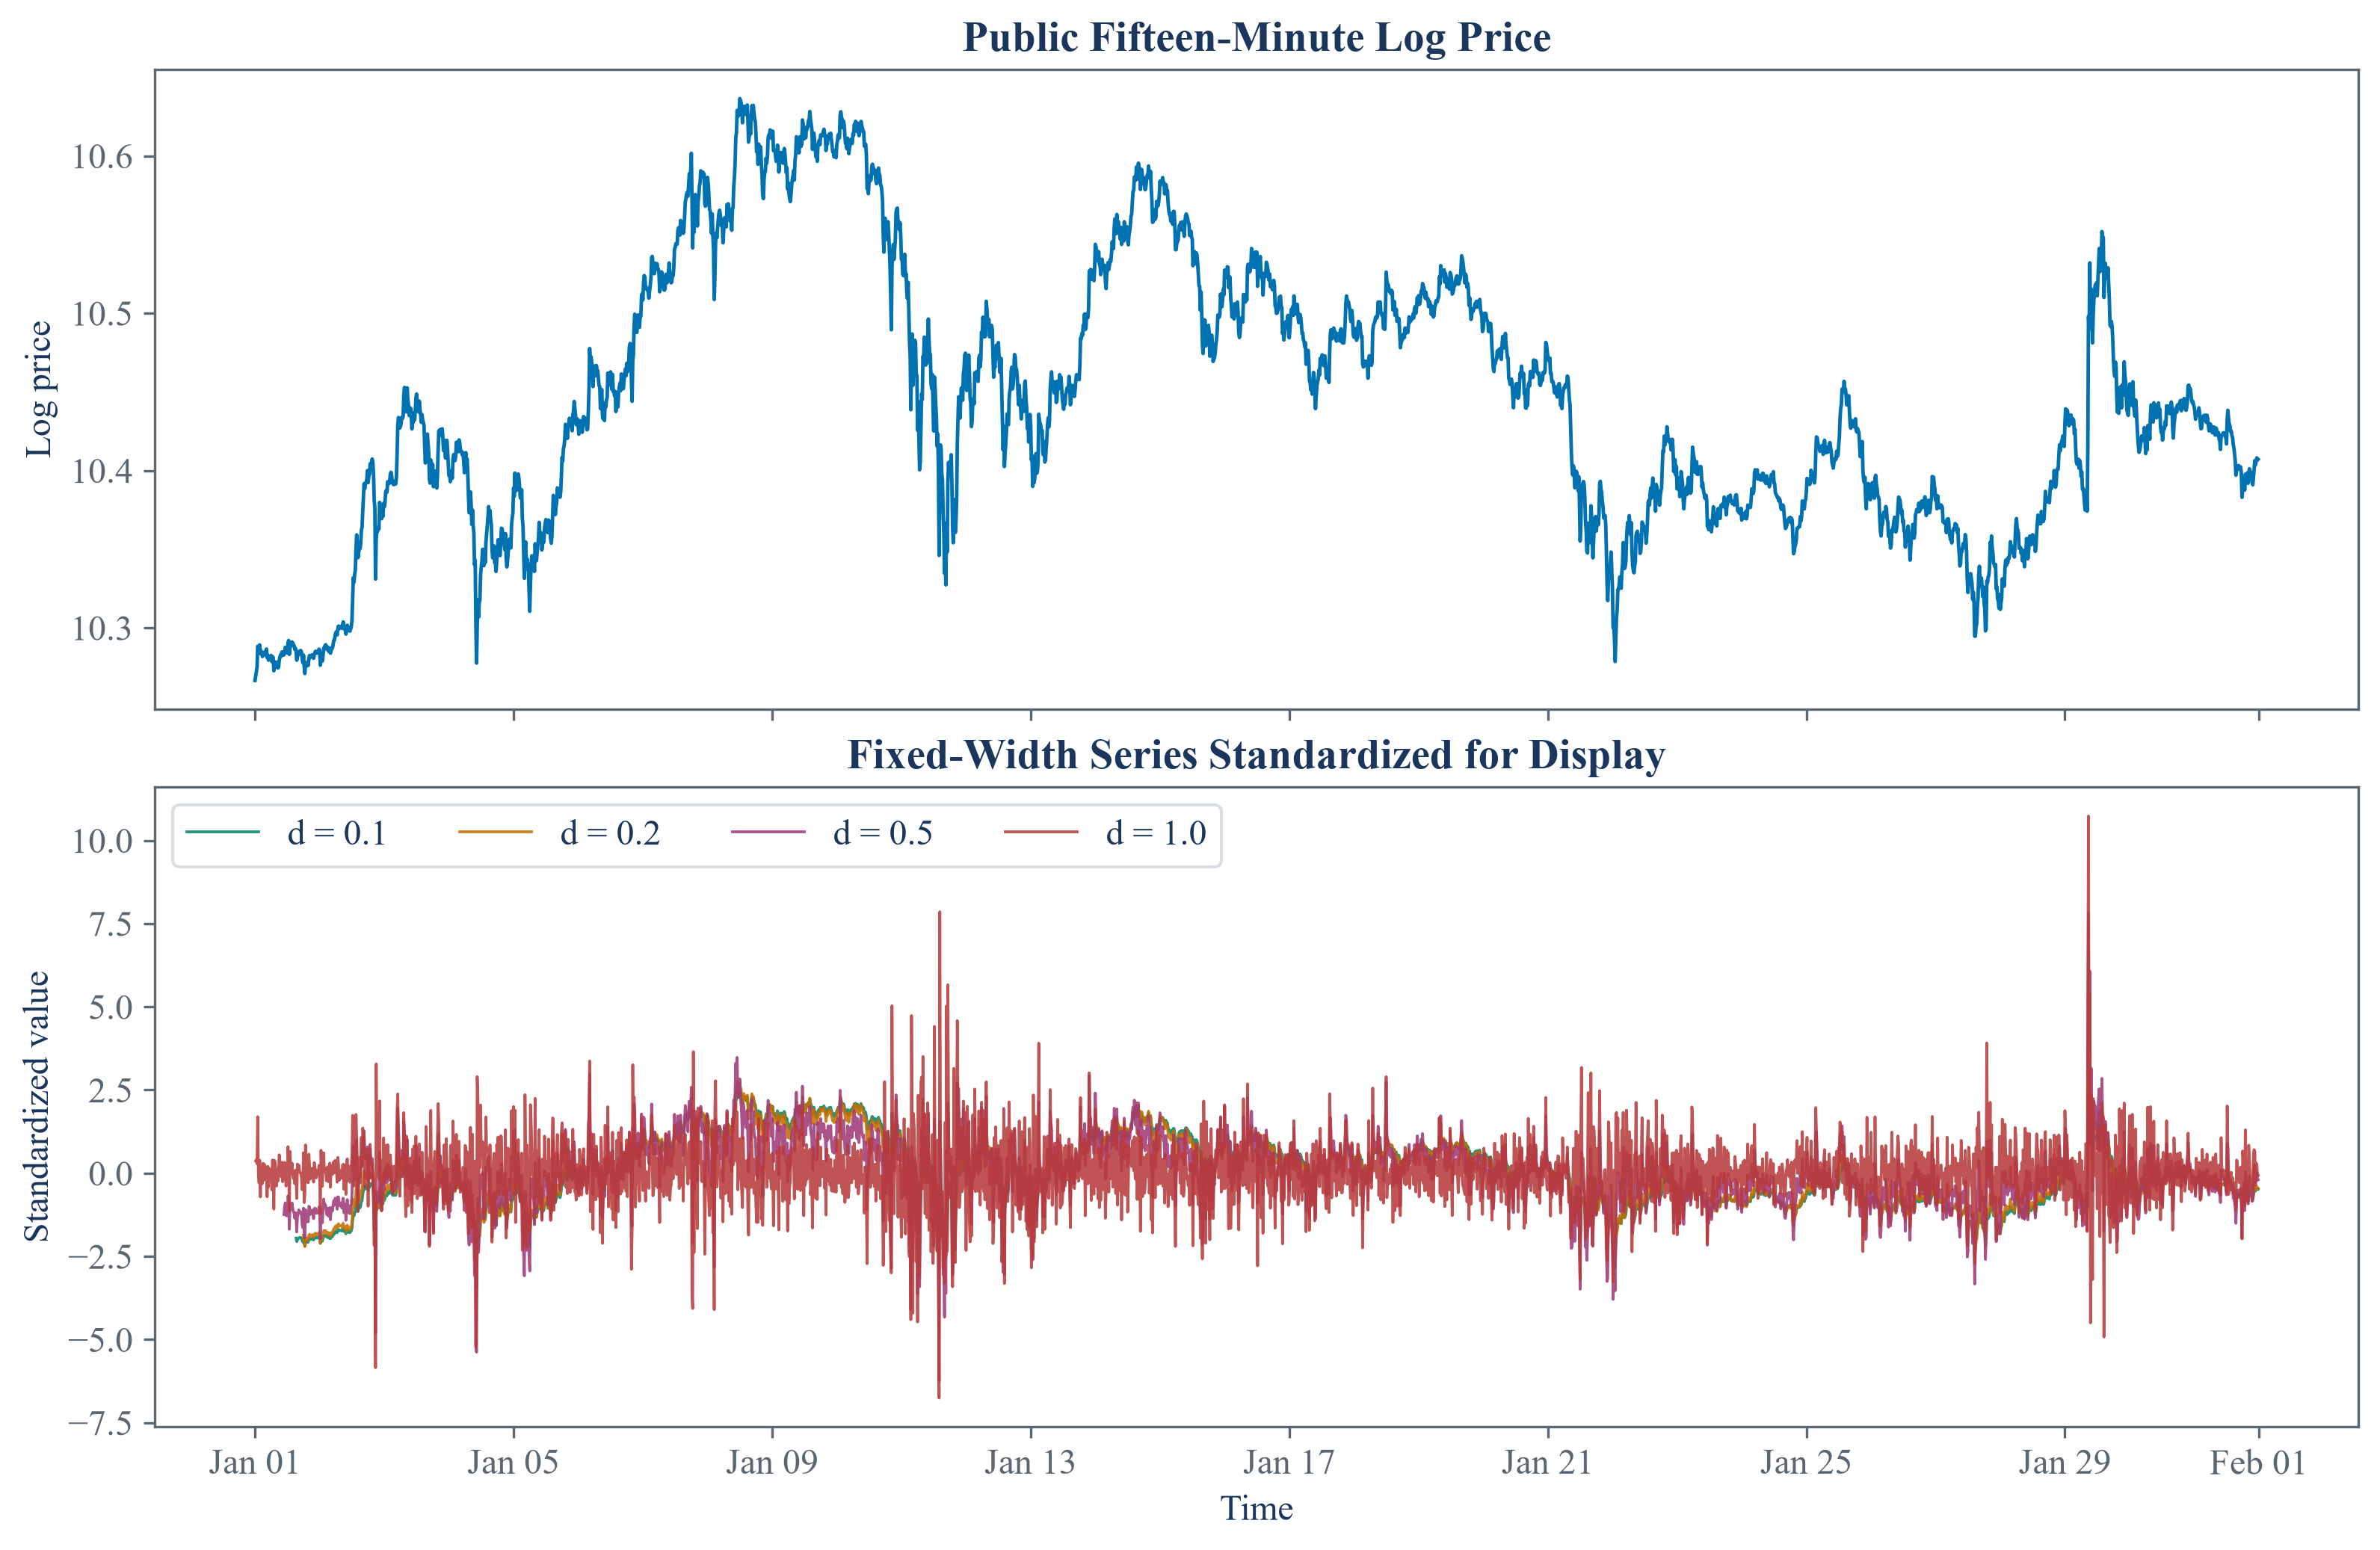

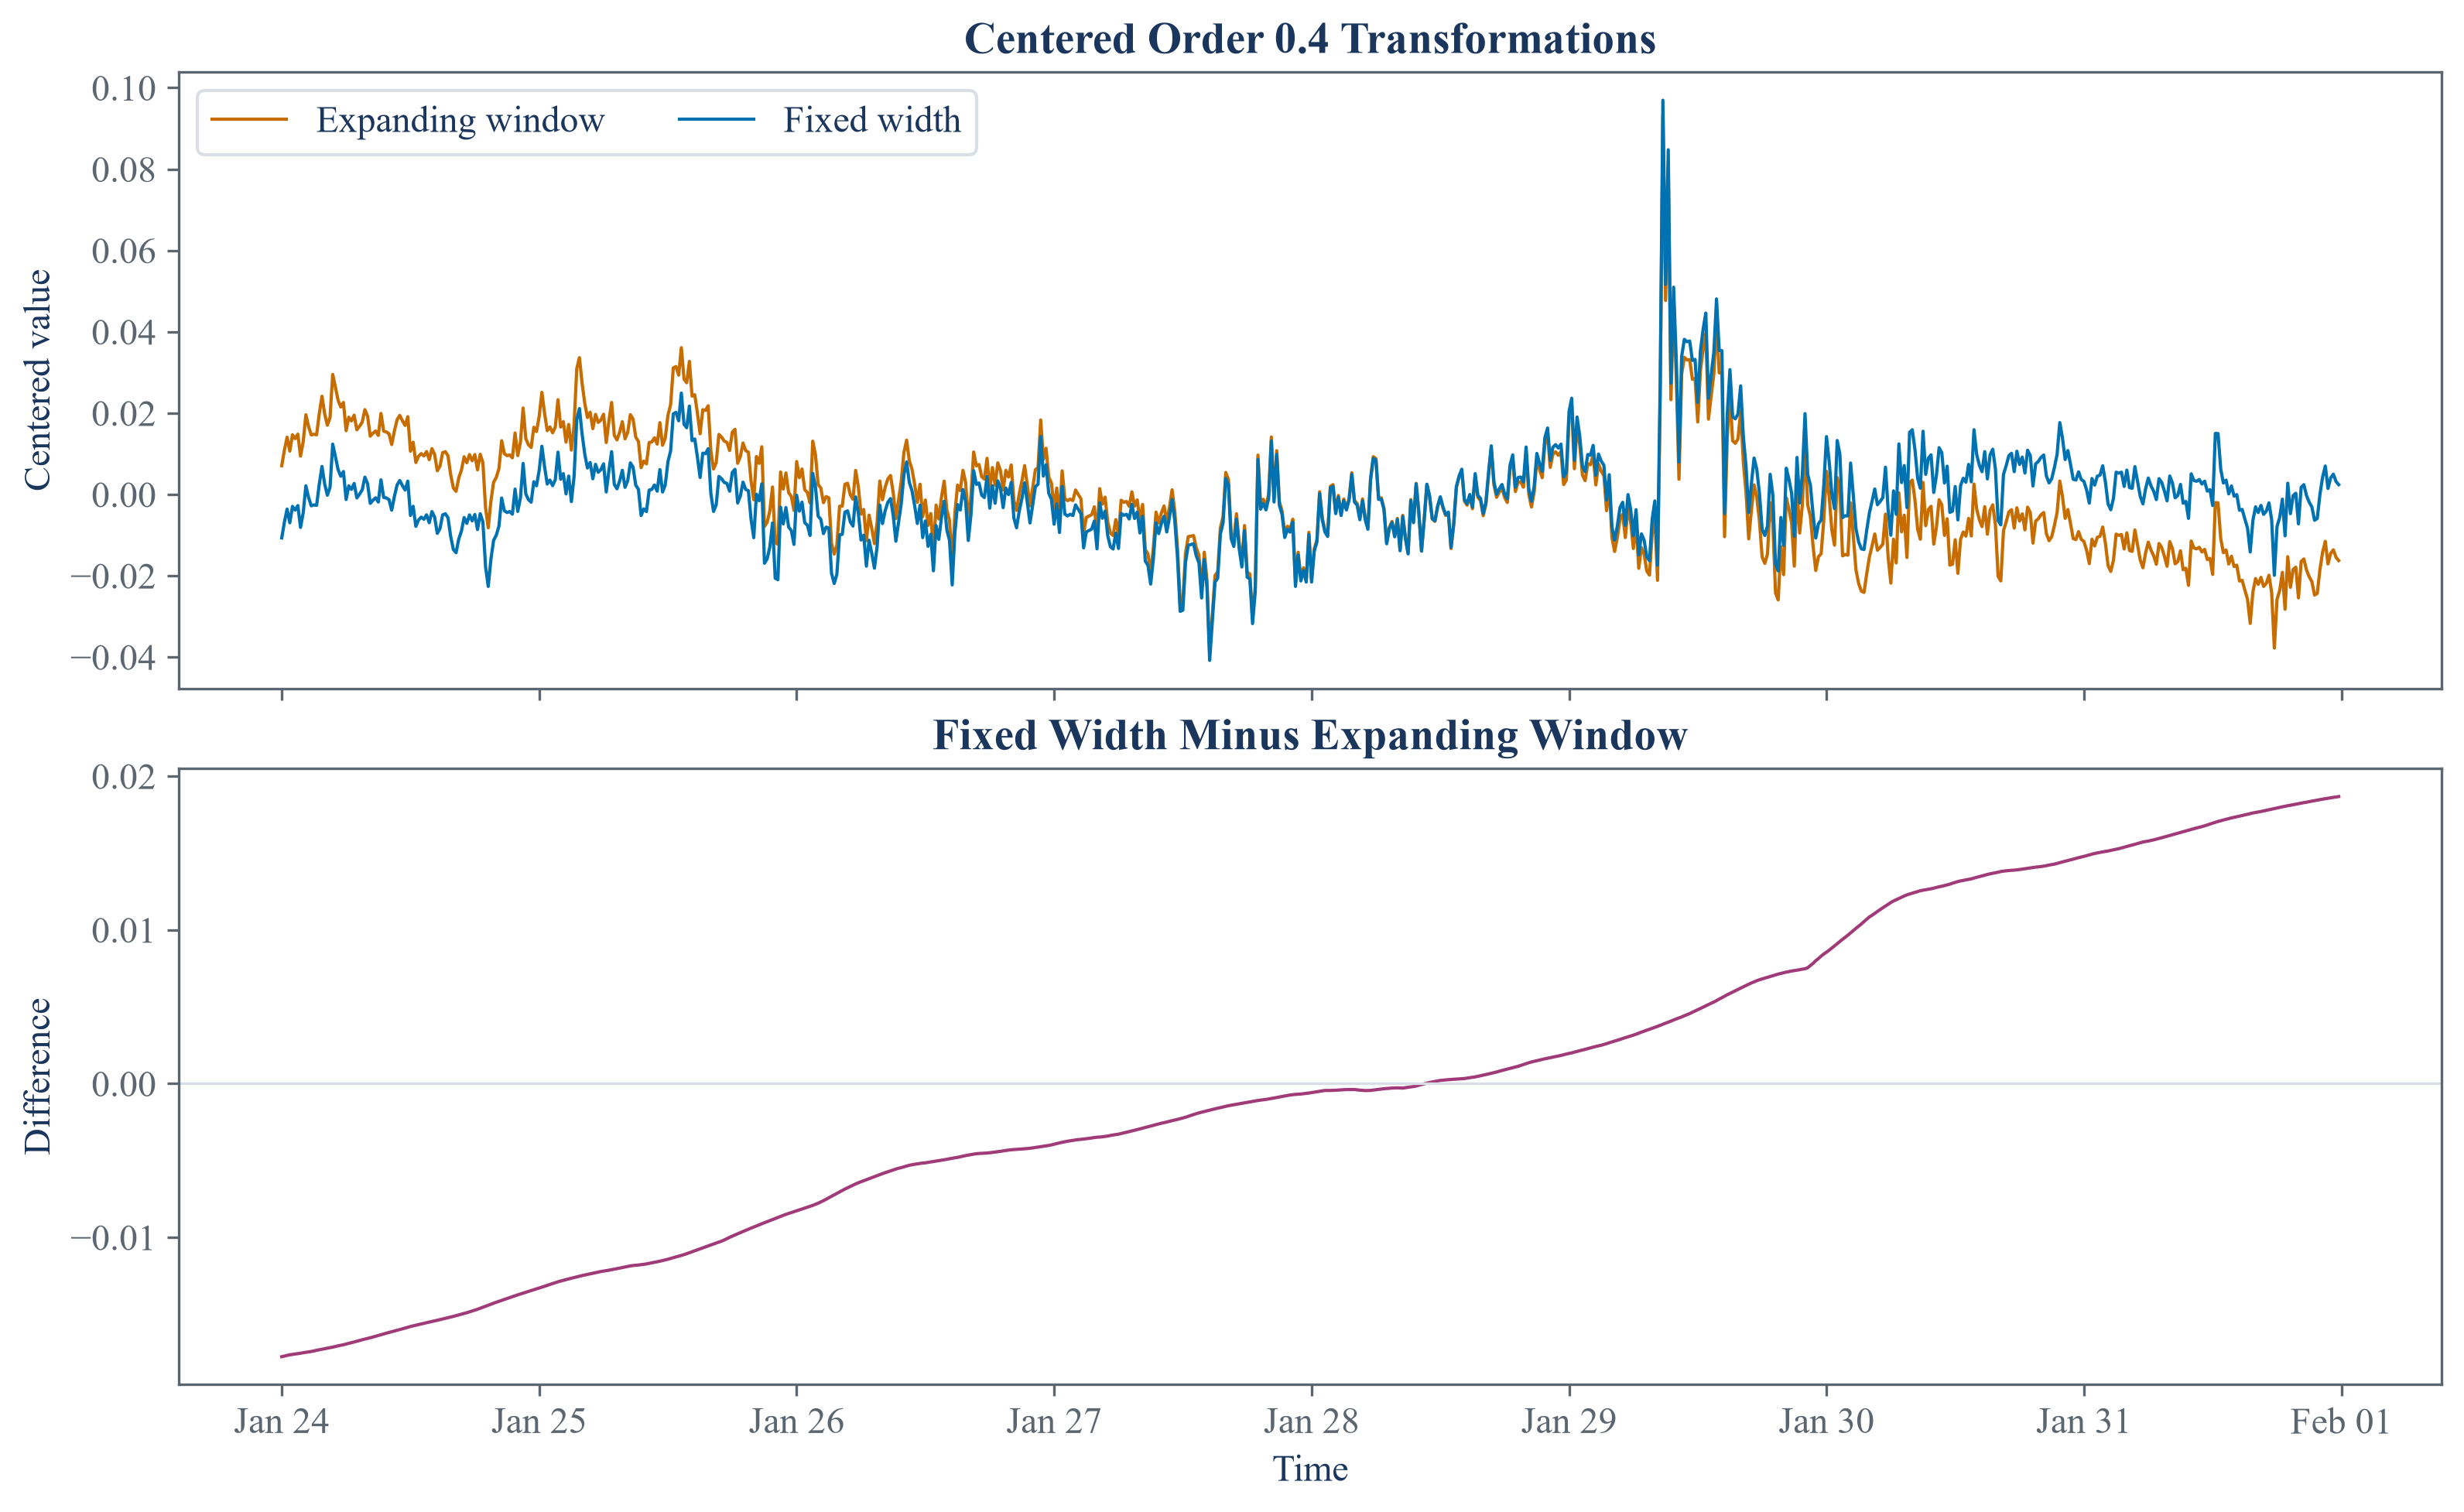

In [3]:
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True, constrained_layout=True)
axes[0].plot(log_price.index, log_price, color=palette["cyan"], linewidth=1.15)
axes[0].set_title("Public Fifteen-Minute Log Price")
axes[0].set_ylabel("Log price")
for degree, color in [(0.1, palette["green"]), (0.2, palette["amber"]), (0.5, palette["violet"]), (1.0, palette["rose"])]:
    values = fixed_outputs[degree]
    standardized = (values - values.mean()) / values.std(ddof=1)
    axes[1].plot(standardized.index, standardized, color=color, linewidth=0.9, alpha=0.88, label=f"d = {degree:.1f}")
axes[1].set_title("Fixed-Width Series Standardized for Display")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Standardized value")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[1].legend(ncol=4)
figure.savefig(FIGURES / "fixed_width_transforms.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "fixed_width_transforms.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "fixed_width_transforms.png")))
plt.close(figure)

common_index = expanding.index.intersection(fixed.index)
expanding_centered = expanding.loc[common_index] - expanding.loc[common_index].mean()
fixed_centered = fixed.loc[common_index] - fixed.loc[common_index].mean()
difference = fixed_centered - expanding_centered
figure, axes = plt.subplots(2, 1, figsize=(10.5, 6.4), sharex=True, constrained_layout=True)
axes[0].plot(common_index, expanding_centered, color=palette["amber"], linewidth=1.0, label="Expanding window")
axes[0].plot(common_index, fixed_centered, color=palette["cyan"], linewidth=1.0, label="Fixed width")
axes[0].set_title("Centered Order 0.4 Transformations")
axes[0].set_ylabel("Centered value")
axes[0].legend(ncol=2)
axes[1].plot(common_index, difference, color=palette["violet"], linewidth=1.0)
axes[1].axhline(0, color=palette["grid"], linewidth=0.8)
axes[1].set_title("Fixed Width Minus Expanding Window")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Difference")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
figure.savefig(FIGURES / "expanding_fixed_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "expanding_fixed_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "expanding_fixed_comparison.png")))
plt.close(figure)

## Memory Retention

Correlation with the aligned original level is used as a simple sample measure of retained linear memory:

$$
M(d,\tau)=\operatorname{Corr}\!\left(X_t,\widetilde X_t^{(d,\tau)}\right),
\qquad -1\leq M(d,\tau)\leq1.
$$

Here, $M(d,\tau)$ is the sample memory measure; $d$ is the difference order; $\tau$ is the weight cutoff. $X_t$ is the original level; $\widetilde X_t^{(d,\tau)}$ is the aligned fixed-width value; $\operatorname{Corr}$ is sample correlation.

## Tests

In [4]:
degree = 0.4
threshold = 1e-3
weights = calculate_weights_ffd(degree, threshold).flatten()[::-1]
manual = np.convolve(log_price.to_numpy(), weights, mode="valid")
released = fractional_difference_fixed_single(log_price, degree, threshold).dropna()
next_lag = len(weights)
next_weight = -weights[-1] * (degree - next_lag + 1) / next_lag
identity = fractional_difference_fixed_single(log_price, 0.0, threshold).dropna()
first_difference = fractional_difference_fixed_single(log_price, 1.0, threshold).dropna()
shifted = fractional_difference_fixed_single(log_price + 2.0, degree, threshold).dropna()
causal_prefix = fractional_difference_fixed_single(log_price.iloc[:-1], degree, threshold).dropna()
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(window_width_summary) == 18
assert np.all(window_width_summary["Smallest retained absolute weight"] >= window_width_summary["Cutoff"])
assert np.all(window_width_summary["First excluded absolute weight"] < window_width_summary["Cutoff"])
assert np.allclose(manual, released.to_numpy())
assert released.index[0] == log_price.index[len(weights) - 1]
assert len(released) == len(log_price) - len(weights) + 1
assert np.allclose(identity.to_numpy(), log_price.to_numpy())
assert np.allclose(first_difference.to_numpy(), log_price.diff().dropna().to_numpy())
assert np.allclose(shifted.to_numpy() - released.to_numpy(), 2.0 * weights.sum())
assert np.allclose(causal_prefix.to_numpy(), released.iloc[:-1].to_numpy())
assert fixed_transform_summary["Correlation with log price"].between(-1, 1).all()
assert fixed_transform_summary.loc[fixed_transform_summary["Order"] == 1.0, "Correlation with log price"].iloc[0] < 0.1
assert fixed_transform_summary.loc[fixed_transform_summary["Order"] == 0.1, "Correlation with log price"].iloc[0] > 0.98
assert len(expanding_fixed_summary) == 2
assert np.isfinite(expanding_fixed_summary.select_dtypes(include=[float, int]).to_numpy()).all()
assert (FIGURES / "fixed_width_transforms.pdf").is_file()
assert (FIGURES / "expanding_fixed_comparison.pdf").is_file()